In [1]:
import os
import json
import glob
import shutil
from datetime import datetime
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq
import torch
import torch.nn as nn
from torch.utils.data import IterableDataset, DataLoader
 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
class Config:
    # Paths
    DATA_DIR = Path("../data")
    FINAL_DATA_DIR = DATA_DIR / "final_data"
    ARTIFACT_DIR = DATA_DIR / "artifacts"
    CF_DIR = ARTIFACT_DIR / "cf"
    PARQUET_DIR = DATA_DIR / "interactions_parquet"
    
    RATINGS_PATH = FINAL_DATA_DIR / "ratings_filtered_by_movie.csv" 
    
    
    # Data Schema
    USER_COL = "userId"
    MOVIE_COL = "movieId"
    RATING_COL = "rating"
    TIMESTAMP_COL = "timestamp"
    
    # Lọc và Chia tập (Top N mới nhất)
    MAX_ROWS_TO_PROCESS = 1_000_000
    TRAIN_RATIO = 0.8
    VAL_RATIO = 0.1
    TEST_RATIO = 0.1
    
    # Hyperparameters
    EMBEDDING_DIM = 64
    INIT_STD = 0.01
    BATCH_SIZE = 1024 
    CHUNK_SIZE = 500000 
    EPOCHS = 10
    LEARNING_RATE = 0.002
    WEIGHT_DECAY = 1e-4
    DROPOUT_RATE = 0.2
    
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    
    # Tiền tố Versioning bằng Timestamp
    # RUN_TIMESTAMP = f"{datetime.now().strftime('%Y%m%d_%H%M%S')}_{1_000_000}"
    RUN_TIMESTAMP = '20261019_124842_1000000'
    
    TOP_K = 10  # Số lượng đề xuất hàng đầu cho mỗi người dùng
    RELEVANCE_THRESHOLD = 4.0  # Rating >= ngưỡng này được xem là phim relevant
    RANDOM_STATE = 42
    
    @classmethod
    def setup(cls):
        cls.PARQUET_DIR.mkdir(parents=True, exist_ok=True)
        cls.CF_DIR.mkdir(parents=True, exist_ok=True)
        (cls.PARQUET_DIR / "train").mkdir(exist_ok=True)
        (cls.PARQUET_DIR / "val").mkdir(exist_ok=True)
        (cls.PARQUET_DIR / "test").mkdir(exist_ok=True)
        print(f"[INFO] Target Device: {cls.DEVICE}")
        print(f"[INFO] Training Run ID: {cls.RUN_TIMESTAMP}")

Config.setup()


[INFO] Target Device: cpu
[INFO] Training Run ID: 20261019_124842_1000000


In [ ]:
# ============================================================
# CELL 0: LOAD DATA + KHAI BÁO BIẾN
# Yêu cầu: đã chạy xong Section 6 của notebook gốc
#   → có Config, dir_path_with_timestamp, mapping_path
# ============================================================
import os, glob, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from scipy.sparse import csr_matrix
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

# ---------- 1. LOAD DATA từ parquet đã split sẵn ----------
TRAIN_PATH = Config.PARQUET_DIR / "train" / "data.parquet"
VAL_PATH   = Config.PARQUET_DIR / "val"   / "data.parquet"
TEST_PATH  = Config.PARQUET_DIR / "test"  / "data.parquet"

train_df = pd.read_parquet(TRAIN_PATH)
val_df   = pd.read_parquet(VAL_PATH)
test_df  = pd.read_parquet(TEST_PATH)

# ---------- 2. ĐỌC MAPPING để lấy num_users / num_movies ----------
# A. Khởi tạo đường dẫn động (Version bằng Timestamp)
dir_path_with_timestamp: Path =  Config.CF_DIR / Config.RUN_TIMESTAMP
save_dir = dir_path_with_timestamp / 'v4'
os.makedirs(dir_path_with_timestamp, exist_ok=True)
os.makedirs(save_dir, exist_ok=True)

def get_timestamped_path(base_dir: Path, postfix_filename: str) -> Path:
    """
    Tạo đường dẫn tệp với tiền tố timestamp.
    
    Args:
        base_dir (Path): Thư mục cơ sở để lưu tệp.
        postfix_filename (str): Tên tệp gốc.
        
    Returns:
        Path: Đường dẫn tệp mới với tiền tố timestamp.
    """
    return base_dir / f"{Config.RUN_TIMESTAMP}_{postfix_filename}"

mapping_path: Path = get_timestamped_path(dir_path_with_timestamp, "mappings.parquet")
mapping_df = pd.read_parquet(mapping_path)   # mapping_path có sẵn từ Section 6
num_users  = int(len(mapping_df[mapping_df["type"] == "user"]))
num_movies = int(len(mapping_df[mapping_df["type"] == "movie"]))

# ---------- 3. BIẾN DÙNG CHUNG ----------
DEVICE       = torch.device(Config.DEVICE)
RATING_COL   = Config.RATING_COL
USER_COL_IDX = "user_idx"
MOVIE_COL_IDX = "movie_idx"
TOP_K        = Config.TOP_K
RUN_ID       = Config.RUN_TIMESTAMP

# ---------- 4. IN RA ĐỂ VERIFY ----------
print("=" * 60)
print(f"TRAIN: {len(train_df):>9,} rows | users={train_df['user_idx'].nunique():>6,}")
print(f"VAL:   {len(val_df):>9,} rows | users={val_df['user_idx'].nunique():>6,}")
print(f"TEST:  {len(test_df):>9,} rows | users={test_df['user_idx'].nunique():>6,}")
print(f"num_users={num_users:,} | num_movies={num_movies:,} | device={DEVICE}")
print(f"rating range: [{train_df[RATING_COL].min()}, {train_df[RATING_COL].max()}]")
print("=" * 60)

TRAIN:   868,600 rows | users=62,683
VAL:      65,700 rows | users=13,140
TEST:     65,700 rows | users=13,140
num_users=62,683 | num_movies=2,583 | device=cpu
rating range: [0.5, 5.0]


c:\Users\THUYEN\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.sparse import csr_matrix
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------- Seen items map (dùng cho TẤT CẢ model) ----------
def build_seen_map(df: pd.DataFrame) -> dict:
    """user_idx -> set(movie_idx) đã tương tác."""
    return df.groupby("user_idx")["movie_idx"].apply(set).to_dict()

TRAIN_SEEN = build_seen_map(train_df)

# ---------- Metrics ----------
def _precision_recall(recs, rel, k):
    hits = len(set(recs[:k]) & rel)
    p = hits / k
    r = hits / len(rel) if rel else 0.0
    return p, r

def _f1(p, r):
    return 2*p*r/(p+r) if (p+r) else 0.0

def _hit_rate(recs, rel, k):
    return 1.0 if set(recs[:k]) & rel else 0.0

def _ndcg(recs, rel, k):
    dcg = sum(1/np.log2(r+2) for r, m in enumerate(recs[:k]) if m in rel)
    idcg = sum(1/np.log2(r+2) for r in range(min(len(rel), k)))
    return dcg/idcg if idcg else 0.0

def _mrr(recs, rel):
    for r, m in enumerate(recs):
        if m in rel: return 1.0/(r+1)
    return 0.0

def _map(recs, rel):
    if not rel: return 0.0
    hits, s = 0, 0.0
    for r, m in enumerate(recs):
        if m in rel:
            hits += 1
            s += hits/(r+1)
    return s/len(rel)

# ---------- Fair Evaluation: tất cả model đều filter seen ----------
def evaluate_recommender(model, eval_df: pd.DataFrame, train_df: pd.DataFrame,
                          k: int = 10, verbose: bool = True) -> dict:
    """
    Đánh giá công bằng: với mỗi user trong eval_df,
    gọi model.recommend(user_idx, seen_items, k) để lấy top-K,
    rồi tính metric so với relevant items trong eval_df.
    """
    seen_map = build_seen_map(train_df)
    rows = []
    for uid, grp in eval_df.groupby("user_idx"):
        uid = int(uid)
        rel = set(grp["movie_idx"].values)
        seen = seen_map.get(uid, set())
        recs = model.recommend(uid, seen, k)
        p, r = _precision_recall(recs, rel, k)
        rows.append({
            "precision@k": p, "recall@k": r, "f1@k": _f1(p, r),
            "hit_rate@k": _hit_rate(recs, rel, k),
            "ndcg@k": _ndcg(recs, rel, k),
            "mrr@k": _mrr(recs, rel),
            "map@k": _map(recs, rel),
        })
    result = {m: float(np.mean([row[m] for row in rows])) for m in rows[0]}
    result["k"] = k
    result["n_users"] = len(rows)
    if verbose:
        print(f"  Users={len(rows)} | P@{k}={result['precision@k']:.4f} "
              f"| R@{k}={result['recall@k']:.4f} | NDCG@{k}={result['ndcg@k']:.4f} "
              f"| HR@{k}={result['hit_rate@k']:.4f}")
    return result

print(f"[OK] Utilities loaded. Device={DEVICE}")

[OK] Utilities loaded. Device=cpu


In [5]:
class PopularityBaseline:
    """Gợi ý phim phổ biến nhất (count interactions trong train)."""
    name = "Popularity"

    def __init__(self, train_df: pd.DataFrame):
        counts = train_df.groupby("movie_idx").size()
        self.ranked = counts.sort_values(ascending=False).index.values
        self.num_movies = len(counts)

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        recs = []
        for i in self.ranked:
            if int(i) not in seen_items:
                recs.append(int(i))
                if len(recs) >= k:
                    break
        return recs

# ---------- Test ----------
pop_model = PopularityBaseline(train_df)
print("\n[Popularity Baseline] Đánh giá trên TEST:")
pop_test = evaluate_recommender(pop_model, test_df, train_df, k=10)


[Popularity Baseline] Đánh giá trên TEST:
  Users=13140 | P@10=0.0610 | R@10=0.1221 | NDCG@10=0.1016 | HR@10=0.4241


In [8]:
class MF_SGD(nn.Module):
    """Biased Matrix Factorization + SGD (MSE loss)."""
    name = "MF-SGD (MSE)"

    def __init__(self, num_users, num_movies, dim=64, init_std=0.01, use_sigmoid=False):
        super().__init__()
        self.user_embedding  = nn.Embedding(num_users, dim)
        self.movie_embedding = nn.Embedding(num_movies, dim)
        self.user_bias  = nn.Embedding(num_users, 1)
        self.movie_bias = nn.Embedding(num_movies, 1)
        self.global_bias = nn.Parameter(torch.zeros(1))
        self.use_sigmoid = use_sigmoid
        self.min_rating, self.max_rating = 0.5, 5.0
        nn.init.normal_(self.user_embedding.weight,  std=init_std)
        nn.init.normal_(self.movie_embedding.weight, std=init_std)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)

    def forward(self, u, m):
        ue = self.user_embedding(u)
        me = self.movie_embedding(m)
        raw = (ue * me).sum(-1) + self.user_bias(u).squeeze(-1) \
              + self.movie_bias(m).squeeze(-1) + self.global_bias
        if self.use_sigmoid:
            raw = (self.max_rating - self.min_rating) * torch.sigmoid(raw) + self.min_rating
        return raw

    @torch.no_grad()
    def predict_all(self, user_idx: int) -> np.ndarray:
        self.eval()
        num_m = self.movie_embedding.num_embeddings
        u = torch.tensor([user_idx]*num_m, dtype=torch.long, device=DEVICE)
        m = torch.arange(num_m, device=DEVICE)
        return self(u, m).cpu().numpy()

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()


def train_mf_sgd(model, train_df, val_df=None, epochs=10, batch_size=4096,
                 lr=2e-3, weight_decay=1e-5, rating_col="rating",
                 patience=3, ckpt_path="best_mf_sgd.pt"):
    """Train MF-SGD với val early stopping dựa trên Val RMSE."""
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    
    users   = torch.tensor(train_df["user_idx"].values, dtype=torch.long)
    movies  = torch.tensor(train_df["movie_idx"].values, dtype=torch.long)
    ratings = torch.tensor(train_df[rating_col].values, dtype=torch.float32)
    n = len(users)
    
    best_rmse, patience_count = float("inf"), 0
    
    for epoch in range(1, epochs+1):
        model.train()
        perm = torch.randperm(n)
        total_loss = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start+batch_size]
            u, m, r = users[idx].to(DEVICE), movies[idx].to(DEVICE), ratings[idx].to(DEVICE)
            pred = model(u, m)
            loss = F.mse_loss(pred, r)
            opt.zero_grad(); loss.backward(); opt.step()
            total_loss += loss.item() * len(idx)
        train_mse = total_loss / n
        
        # Val
        if val_df is not None and len(val_df):
            model.eval()
            with torch.no_grad():
                vu = torch.tensor(val_df["user_idx"].values, dtype=torch.long, device=DEVICE)
                vm = torch.tensor(val_df["movie_idx"].values, dtype=torch.long, device=DEVICE)
                vr = torch.tensor(val_df[rating_col].values, dtype=torch.float32, device=DEVICE)
                val_mse = 0.0
                for s in range(0, len(vu), batch_size):
                    pred = model(vu[s:s+batch_size], vm[s:s+batch_size])
                    val_mse += F.mse_loss(pred, vr[s:s+batch_size], reduction="sum").item()
                val_mse /= len(vu)
            val_rmse = np.sqrt(val_mse)
            print(f"Epoch {epoch:2d} | TrainMSE={train_mse:.4f} | ValRMSE={val_rmse:.4f}")
            if val_rmse < best_rmse - 1e-4:
                best_rmse = val_rmse
                torch.save(model.state_dict(), ckpt_path)
                patience_count = 0
            else:
                patience_count += 1
                if patience_count >= patience:
                    print(f"  Early stop at epoch {epoch}. Best ValRMSE={best_rmse:.4f}")
                    break
        else:
            print(f"Epoch {epoch:2d} | TrainMSE={train_mse:.4f}")
    
    if val_df is not None and __import__("os").path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


# ---------- Train & Test ----------
mf_sgd = MF_SGD(num_users, num_movies, dim=64, use_sigmoid=False)
checkpoint_path = get_timestamped_path(dir_path_with_timestamp, "best_mf_sgd.pt")
mf_sgd = train_mf_sgd(mf_sgd, train_df, val_df, epochs=15, batch_size=4096,
                      lr=2e-3, patience=3, ckpt_path=checkpoint_path)

print("\n[MF-SGD] Đánh giá trên TEST:")
mf_test = evaluate_recommender(mf_sgd, test_df, train_df, k=10)

Epoch  1 | TrainMSE=7.7578 | ValRMSE=1.1524
Epoch  2 | TrainMSE=1.2480 | ValRMSE=0.9516
Epoch  3 | TrainMSE=0.8672 | ValRMSE=0.9299
Epoch  4 | TrainMSE=0.7816 | ValRMSE=0.9188
Epoch  5 | TrainMSE=0.7355 | ValRMSE=0.9094
Epoch  6 | TrainMSE=0.6964 | ValRMSE=0.9002
Epoch  7 | TrainMSE=0.6607 | ValRMSE=0.8947
Epoch  8 | TrainMSE=0.6300 | ValRMSE=0.8905
Epoch  9 | TrainMSE=0.5987 | ValRMSE=0.8871
Epoch 10 | TrainMSE=0.5630 | ValRMSE=0.8840
Epoch 11 | TrainMSE=0.5206 | ValRMSE=0.8799
Epoch 12 | TrainMSE=0.4723 | ValRMSE=0.8770
Epoch 13 | TrainMSE=0.4227 | ValRMSE=0.8735
Epoch 14 | TrainMSE=0.3737 | ValRMSE=0.8727
Epoch 15 | TrainMSE=0.3305 | ValRMSE=0.8738

[MF-SGD] Đánh giá trên TEST:
  Users=13140 | P@10=0.0493 | R@10=0.0985 | NDCG@10=0.0842 | HR@10=0.3669


In [18]:
class BPR_MF(nn.Module):
    """BPR-MF: tối ưu thứ tự, không cần MSE."""
    name = "BPR-MF"

    def __init__(self, num_users, num_movies, dim=64, init_std=0.01):
        super().__init__()
        self.user_embedding  = nn.Embedding(num_users, dim)
        self.movie_embedding = nn.Embedding(num_movies, dim)
        nn.init.normal_(self.user_embedding.weight,  std=init_std)
        nn.init.normal_(self.movie_embedding.weight, std=init_std)

    def forward(self, u, i, j):
        uv = self.user_embedding(u)
        iv = self.movie_embedding(i)
        jv = self.movie_embedding(j)
        return (uv*iv).sum(-1), (uv*jv).sum(-1)

    @torch.no_grad()
    def predict_all(self, user_idx: int) -> np.ndarray:
        self.eval()
        u_vec = self.user_embedding.weight[user_idx]
        return (self.movie_embedding.weight @ u_vec).cpu().numpy()

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()


def train_bpr(model, train_df, num_movies, val_df=None, epochs=20,
              batch_size=4096, lr=1e-3, weight_decay=1e-6,
              patience=3, ckpt_path="best_bpr.pt", seed=42):
    """Train BPR với negative sampling và early stopping trên Val NDCG."""
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    
    users_arr = train_df["user_idx"].values
    items_arr = train_df["movie_idx"].values
    user_pos  = train_df.groupby("user_idx")["movie_idx"].apply(set).to_dict()
    n = len(users_arr)
    
    rng = np.random.default_rng(seed)
    best_ndcg, patience_count = -np.inf, 0
    
    for epoch in range(1, epochs+1):
        model.train()
        perm = rng.permutation(n)
        total_loss = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start+batch_size]
            u_np = users_arr[idx]
            i_np = items_arr[idx]
            
            # Negative sampling (1 retry vectorized)
            neg = rng.integers(0, num_movies, size=len(idx))
            for k_ in range(len(idx)):
                if neg[k_] in user_pos.get(u_np[k_], ()):
                    for _ in range(5):
                        cand = rng.integers(0, num_movies)
                        if cand not in user_pos.get(u_np[k_], ()):
                            neg[k_] = cand; break
            
            u = torch.tensor(u_np, dtype=torch.long, device=DEVICE)
            i = torch.tensor(i_np, dtype=torch.long, device=DEVICE)
            j = torch.tensor(neg, dtype=torch.long, device=DEVICE)
            
            pos_s, neg_s = model(u, i, j)
            loss = -F.logsigmoid(pos_s - neg_s).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            total_loss += loss.item() * len(idx)
        
        print(f"Epoch {epoch:2d} | BPR loss={total_loss/n:.4f}")
        
        if val_df is not None and len(val_df):
            val_metrics = evaluate_recommender(model, val_df, train_df, k=10, verbose=False)
            val_ndcg = val_metrics["ndcg@k"]
            print(f"           Val NDCG@10={val_ndcg:.4f} | HR@10={val_metrics['hit_rate@k']:.4f}")
            if val_ndcg > best_ndcg + 1e-4:
                best_ndcg = val_ndcg
                torch.save(model.state_dict(), ckpt_path)
                patience_count = 0
            else:
                patience_count += 1
                if patience_count >= patience:
                    print(f"  Early stop at epoch {epoch}. Best NDCG@{10}={best_ndcg:.4f}")
                    break
    
    if val_df is not None and __import__("os").path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


# ---------- Train & Test ----------
bpr_mf = BPR_MF(num_users, num_movies, dim=64)
best_bpr_path = get_timestamped_path(dir_path_with_timestamp, "best_bpr.pt")
bpr_mf = train_bpr(bpr_mf, train_df, num_movies, val_df,
                   epochs=10, batch_size=4096, lr=1e-2, patience=3,
                   ckpt_path=best_bpr_path)

print("\n[BPR-MF] Đánh giá trên TEST:")
bpr_test = evaluate_recommender(bpr_mf, test_df, train_df, k=10)

Epoch  1 | BPR loss=0.2532
           Val NDCG@10=0.1190 | HR@10=0.4663
Epoch  2 | BPR loss=0.1050
           Val NDCG@10=0.1246 | HR@10=0.4877
Epoch  3 | BPR loss=0.0939
           Val NDCG@10=0.1282 | HR@10=0.5016
Epoch  4 | BPR loss=0.0852
           Val NDCG@10=0.1301 | HR@10=0.5006
Epoch  5 | BPR loss=0.0799
           Val NDCG@10=0.1322 | HR@10=0.5078
Epoch  6 | BPR loss=0.0751
           Val NDCG@10=0.1310 | HR@10=0.5097
Epoch  7 | BPR loss=0.0707
           Val NDCG@10=0.1330 | HR@10=0.5170
Epoch  8 | BPR loss=0.0678
           Val NDCG@10=0.1343 | HR@10=0.5184
Epoch  9 | BPR loss=0.0655
           Val NDCG@10=0.1341 | HR@10=0.5211
Epoch 10 | BPR loss=0.0632
           Val NDCG@10=0.1354 | HR@10=0.5251

[BPR-MF] Đánh giá trên TEST:
  Users=13140 | P@10=0.0689 | R@10=0.1378 | NDCG@10=0.1155 | HR@10=0.4715


In [10]:
import implicit

class ALS_Implicit:
    """Implicit ALS — dùng đúng chuẩn: binarize positive, alpha cho confidence."""
    name = "ALS-Implicit"

    def __init__(self, train_df, num_users, num_movies, factors=64,
                 alpha=40.0, reg=0.05, iterations=30, rating_threshold=3.5):
        # Chỉ coi rating >= 3.5 là positive (giải quyết issue #3)
        pos = train_df[train_df["rating"] >= rating_threshold]
        self.matrix = csr_matrix(
            (np.ones(len(pos), dtype=np.float32),
             (pos["user_idx"].values, pos["movie_idx"].values)),
            shape=(num_users, num_movies)
        )
        self.model = implicit.als.AlternatingLeastSquares(
            factors=factors, regularization=reg, alpha=alpha,
            iterations=iterations, random_state=42,
            use_gpu=torch.cuda.is_available()
        )
        self.model.fit(self.matrix)
        self._num_movies = num_movies

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        # implicit.recommend đã tự filter seen của chính nó, nhưng ta cần
        # thêm filter cho "seen_items" từ ngoài (đồng bộ với các model khác)
        N = min(k + len(seen_items), self._num_movies - 1)
        ids, _ = self.model.recommend(
            user_idx, self.matrix[user_idx], N=N, filter_already_liked_items=True
        )
        recs = [int(i) for i in ids if int(i) not in seen_items][:k]
        return recs


# ---------- Train & Test ----------
als_model = ALS_Implicit(train_df, num_users, num_movies,
                          factors=64, alpha=40.0, reg=0.05, iterations=30)

print("\n[ALS-Implicit] Đánh giá trên TEST:")
als_test = evaluate_recommender(als_model, test_df, train_df, k=10)

c:\Users\THUYEN\AppData\Local\Programs\Python\Python311\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 12 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()
100%|██████████| 30/30 [00:06<00:00,  4.68it/s]



[ALS-Implicit] Đánh giá trên TEST:
  Users=13140 | P@10=0.0522 | R@10=0.1044 | NDCG@10=0.0872 | HR@10=0.4018


In [ ]:
class NCF(nn.Module):
    """Neural CF: MLP trên concat [user_emb, item_emb], train bằng BCE (implicit)."""
    name = "NCF"

    def __init__(self, num_users, num_movies, dim=32, hidden=(128,64,32),
                 dropout=0.2, init_std=0.01):
        super().__init__()
        self.user_emb  = nn.Embedding(num_users, dim)
        self.movie_emb = nn.Embedding(num_movies, dim)
        nn.init.normal_(self.user_emb.weight,  std=init_std)
        nn.init.normal_(self.movie_emb.weight, std=init_std)
        layers, in_dim = [], dim*2
        for h in hidden:
            layers += [nn.Linear(in_dim, h), nn.ReLU(), nn.Dropout(dropout)]
            in_dim = h
        layers += [nn.Linear(in_dim, 1)]
        self.mlp = nn.Sequential(*layers)

    def forward(self, u, m):
        x = torch.cat([self.user_emb(u), self.movie_emb(m)], dim=-1)
        return self.mlp(x).squeeze(-1)

    @torch.no_grad()
    def predict_all(self, user_idx: int) -> np.ndarray:
        self.eval()
        num_m = self.movie_emb.num_embeddings
        u = torch.tensor([user_idx]*num_m, dtype=torch.long, device=DEVICE)
        m = torch.arange(num_m, device=DEVICE)
        return torch.sigmoid(self(u, m)).cpu().numpy()

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()


def train_ncf(model, train_df, num_movies, val_df=None, epochs=10,
              batch_size=4096, lr=1e-3, weight_decay=1e-6, patience=3,
              ckpt_path="best_ncf.pt", seed=42):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    users_arr = train_df["user_idx"].values
    items_arr = train_df["movie_idx"].values
    user_pos  = train_df.groupby("user_idx")["movie_idx"].apply(set).to_dict()
    n = len(users_arr)
    rng = np.random.default_rng(seed)
    best_ndcg, patience_count = -np.inf, 0

    for epoch in range(1, epochs+1):
        model.train()
        perm = rng.permutation(n)
        total_loss = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start+batch_size]
            u_np = users_arr[idx]; i_np = items_arr[idx]
            neg = rng.integers(0, num_movies, size=len(idx))
            for k_ in range(len(idx)):
                if neg[k_] in user_pos.get(u_np[k_], ()):
                    for _ in range(5):
                        cand = rng.integers(0, num_movies)
                        if cand not in user_pos.get(u_np[k_], ()):
                            neg[k_] = cand; break
            # pos + neg batch
            u_p = torch.tensor(u_np, dtype=torch.long, device=DEVICE)
            i_p = torch.tensor(i_np, dtype=torch.long, device=DEVICE)
            u_n = u_p; i_n = torch.tensor(neg, dtype=torch.long, device=DEVICE)
            pos_score = model(u_p, i_p)
            neg_score = model(u_n, i_n)
            loss = F.binary_cross_entropy_with_logits(
                torch.cat([pos_score, neg_score]),
                torch.cat([torch.ones_like(pos_score), torch.zeros_like(neg_score)])
            )
            opt.zero_grad(); loss.backward(); opt.step()
            total_loss += loss.item() * len(idx)
        print(f"Epoch {epoch:2d} | NCF loss={total_loss/n:.4f}")
        if val_df is not None and len(val_df):
            val_metrics = evaluate_recommender(model, val_df, train_df, k=10, verbose=False)
            val_ndcg = val_metrics["ndcg@k"]
            print(f"           Val NDCG@10={val_ndcg:.4f} | HR@10={val_metrics['hit_rate@k']:.4f}")
            if val_ndcg > best_ndcg + 1e-4:
                best_ndcg = val_ndcg
                torch.save(model.state_dict(), ckpt_path)
                patience_count = 0
            else:
                patience_count += 1
                if patience_count >= patience:
                    print(f"  Early stop. Best NDCG@10={best_ndcg:.4f}")
                    break
    if val_df is not None and __import__("os").path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


# ---------- Train & Test ----------
ncf_model = NCF(num_users, num_movies, dim=32, hidden=(128,64,32), dropout=0.2)
best_ncf_path = get_timestamped_path(dir_path_with_timestamp, "best_ncf.pt")
ncf_model = train_ncf(ncf_model, train_df, num_movies, val_df,
                       epochs=15, batch_size=4096, lr=1e-3, patience=3,
                       ckpt_path=best_ncf_path)

print("\n[NCF] Đánh giá trên TEST:")
ncf_test = evaluate_recommender(ncf_model, test_df, train_df, k=10)


BẢNG SO SÁNH — TẤT CẢ ĐÃ FILTER SEEN ITEMS (@k=10)


,precision@k,recall@k,f1@k,hit_rate@k,ndcg@k,mrr@k,map@k
Model,,,,,,,
Popularity,0.0610,0.1221,0.0814,0.4241,0.1016,0.1709,0.0501
MF-SGD,0.0493,0.0985,0.0657,0.3669,0.0842,0.1504,0.0408
BPR-MF,0.0689,0.1378,0.0918,0.4715,0.1155,0.1936,0.0574
ALS-Implicit,0.0522,0.1044,0.0696,0.4018,0.0872,0.1552,0.0405
NCF,0.0611,0.1223,0.0815,0.4253,0.1021,0.1727,0.0504


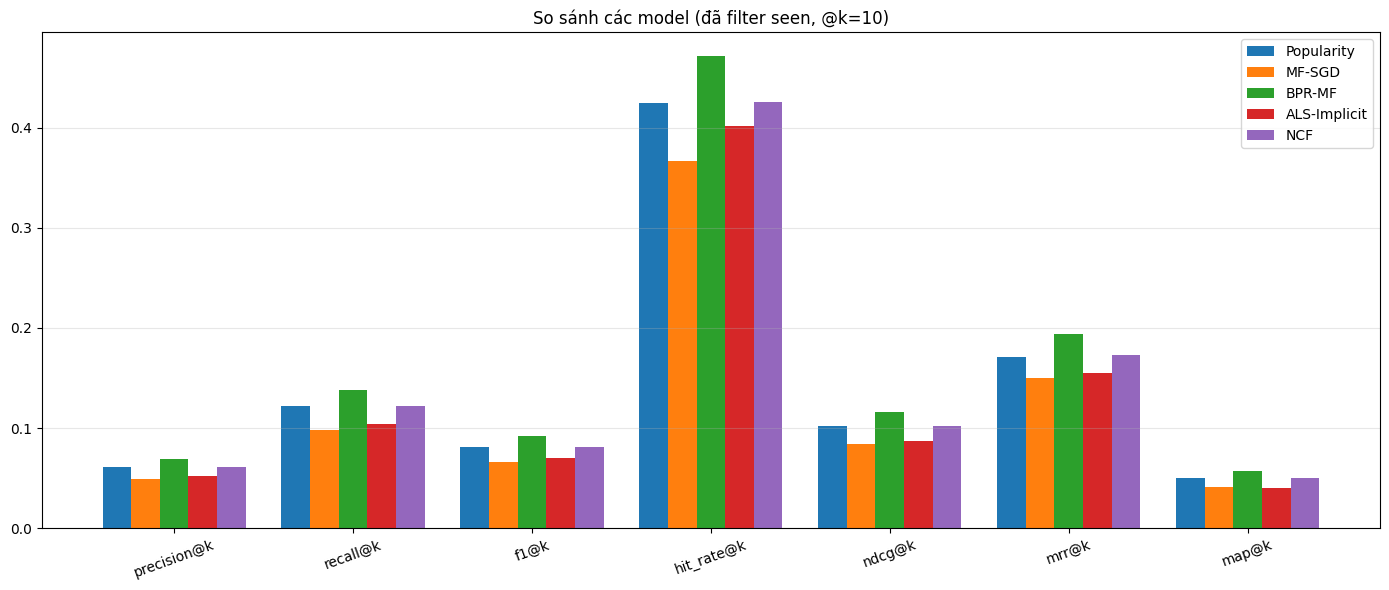

[Saved] ..\data\artifacts\cf\20261019_124842_1000000\20261019_124842_1000000_comparison_FINAL.csv


In [20]:
import pandas as pd

results = []
for name, res in [
    ("Popularity", pop_test),
    ("MF-SGD",     mf_test),
    ("BPR-MF",     bpr_test),
    ("ALS-Implicit", als_test),
    ("NCF",         ncf_test)
]:
    results.append({"Model": name, **{k:v for k,v in res.items() if k not in ("k","n_users")}})

df_compare = pd.DataFrame(results).set_index("Model")
df_compare = df_compare[["precision@k","recall@k","f1@k","hit_rate@k","ndcg@k","mrr@k","map@k"]]
df_compare = df_compare.round(4)

print("\n" + "="*90)
print("BẢNG SO SÁNH — TẤT CẢ ĐÃ FILTER SEEN ITEMS (@k=10)")
print("="*90)
display(df_compare)

# Vẽ bar chart
import matplotlib.pyplot as plt
metrics = ["precision@k","recall@k","f1@k","hit_rate@k","ndcg@k","mrr@k","map@k"]
x = np.arange(len(metrics)); w = 0.8/len(df_compare)
fig, ax = plt.subplots(figsize=(14, 6))
for i, model in enumerate(df_compare.index):
    ax.bar(x + (i - len(df_compare)/2 + 0.5)*w, df_compare.loc[model, metrics], w, label=model)
ax.set_xticks(x); ax.set_xticklabels(metrics, rotation=20)
ax.set_title("So sánh các model (đã filter seen, @k=10)")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
model_comparison_path = get_timestamped_path(dir_path_with_timestamp, "comparison_FINAL.png")
plt.savefig(model_comparison_path, dpi=150)
plt.show()

# Lưu CSV
compare_csv_path = get_timestamped_path(dir_path_with_timestamp, "comparison_FINAL.csv")
df_compare.to_csv(compare_csv_path)
print(f"[Saved] {compare_csv_path}")

In [17]:
def tune_bpr(grid, train_df, val_df, num_movies):
    results = []
    for cfg in grid:
        print(f"\n[Grid Search] Training BPR-MF with config: {cfg}")
        m = BPR_MF(num_users, num_movies, dim=cfg["dim"])
        
        tune_bpr_path = get_timestamped_path(dir_path_with_timestamp, f"tune_bpr_dim{cfg['dim']}_lr{cfg['lr']}.pt")
        m = train_bpr(m, train_df, num_movies, val_df,
                      epochs=cfg["epochs"], lr=cfg["lr"], batch_size=4096,
                      patience=2, ckpt_path=tune_bpr_path, seed=42)
        val_m = evaluate_recommender(m, val_df, train_df, k=10, verbose=False)
        results.append({**cfg, **{f"val_{k}":v for k,v in val_m.items() if k not in ("k","n_users")}})
        print(f"  → {cfg} | Val NDCG@10={val_m['ndcg@k']:.4f}")
        
    return pd.DataFrame(results).sort_values("val_ndcg@k", ascending=False)

# Ví dụ grid nhỏ — chạy hết khoảng 15–25 phút trên CPU
grid = [
    {"dim":32, "lr":1e-3, "epochs":10},
    {"dim":64, "lr":1e-3, "epochs":10},
    {"dim":64, "lr":2e-3, "epochs":10},
    {"dim":128,"lr":1e-3, "epochs":10},
]
df_tune = tune_bpr(grid, train_df, val_df, num_movies)
display(df_tune)


[Grid Search] Training BPR-MF with config: {'dim': 32, 'lr': 0.001, 'epochs': 10}
Epoch  1 | BPR loss=0.6168
           Val NDCG@10=0.1188 | HR@10=0.4633
Epoch  2 | BPR loss=0.2737
           Val NDCG@10=0.1128 | HR@10=0.4418
Epoch  3 | BPR loss=0.1675
           Val NDCG@10=0.1110 | HR@10=0.4392
  Early stop at epoch 3. Best NDCG@10=0.1188
  → {'dim': 32, 'lr': 0.001, 'epochs': 10} | Val NDCG@10=0.1188

[Grid Search] Training BPR-MF with config: {'dim': 64, 'lr': 0.001, 'epochs': 10}
Epoch  1 | BPR loss=0.5726
           Val NDCG@10=0.1155 | HR@10=0.4552
Epoch  2 | BPR loss=0.2054
           Val NDCG@10=0.1120 | HR@10=0.4435
Epoch  3 | BPR loss=0.1411
           Val NDCG@10=0.1125 | HR@10=0.4473
  Early stop at epoch 3. Best NDCG@10=0.1155
  → {'dim': 64, 'lr': 0.001, 'epochs': 10} | Val NDCG@10=0.1155

[Grid Search] Training BPR-MF with config: {'dim': 64, 'lr': 0.002, 'epochs': 10}
Epoch  1 | BPR loss=0.4315
           Val NDCG@10=0.1126 | HR@10=0.4469
Epoch  2 | BPR loss=0.1378
  

,dim,lr,epochs,val_precision@k,val_recall@k,val_f1@k,val_hit_rate@k,val_ndcg@k,val_mrr@k,val_map@k
2,64,0.002,10,0.076568,0.153135,0.102090,0.494444,0.126149,0.201460,0.064205
0,32,0.001,10,0.070708,0.141416,0.094277,0.463318,0.118765,0.195135,0.060922
1,64,0.001,10,0.069186,0.138371,0.092248,0.455175,0.115472,0.187531,0.059079
3,128,0.001,10,0.068638,0.137275,0.091517,0.450609,0.114844,0.187051,0.058902
